# 02 · Feature Engineering

The EDA showed three things:
- The raw money columns mostly measure **size**.
- The behavioural columns carry the **risk** signal.
- The data sources can be **cross-checked** against each other.

This notebook builds analyst-style features on top of the raw data and tests whether they carry signal.

Full definitions: `docs/FEATURE_DICTIONARY.md`. Code: `src/msme_health/features.py`. The same function runs in training, in the API and in the dashboard, so there is no training/serving skew.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression

from msme_health.config import DATA_PATH, NUMERIC_RAW
from msme_health.features import DERIVED, LABELS, add_derived

sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams["figure.dpi"] = 110
raw = pd.read_csv(DATA_PATH)
df = add_derived(raw)
df["logit_pd"] = np.log(df.Probability_of_Default / (1 - df.Probability_of_Default))
df[DERIVED].describe(percentiles=[0.01, 0.5, 0.99]).T.round(3)

,count,mean,std,min,1%,50%,99%,max
GST_Bank_Gap,50000.0,0.030,0.070,-0.272,-0.131,0.030,0.194,3.300000e-01
GST_Turnover_Gap,50000.0,-0.020,0.080,-0.384,-0.205,-0.020,0.169,3.000000e-01
UPI_Share_of_Credits,50000.0,0.368,0.202,0.030,0.054,0.332,0.849,1.281000e+00
Net_Surplus_Ratio,50000.0,0.204,0.096,-0.150,-0.021,0.204,0.427,5.500000e-01
Balance_Cover_Months,50000.0,0.685,0.375,0.001,0.057,0.626,1.847,3.584000e+00
EMI_Burden,50000.0,0.066,0.109,0.000,0.000,0.000,0.350,3.500000e-01
Gross_Margin_GST,50000.0,0.370,0.130,0.050,0.068,0.369,0.677,8.000000e-01
Payroll_to_Sales,50000.0,0.185,0.144,0.007,0.033,0.146,0.744,2.304000e+00
Revenue_per_Employee,50000.0,2162584.026,1329266.331,232068.000,417146.340,1848153.167,6779235.223,1.559907e+07
Lean_Month_Surplus_Ratio,50000.0,0.042,0.130,-1.787,-0.348,0.052,0.298,4.970000e-01


## 1. The derived features

| Family | Features | Credit question it answers |
|---|---|---|
| Cross-source consistency | GST-bank gap, GST-turnover gap, UPI share of credits | Do the sources tell the same story? |
| Cash-flow capacity | Net surplus ratio, balance cover months, EMI burden | Is there money left to repay a loan? |
| Business economics | Gross margin, payroll-to-sales, revenue per employee | Is the business model healthy? |
| Seasonality stress | Lean-month surplus ratio | Can it pay in its *worst* month? |
| Credit file | Thin-file flag | Is the bureau empty (NTC)? |

### The lean-month stress test, step by step

1. Seasonality index *s* says how far sales drop below average in the lean month (sales × (1 − s)).
2. Costs that move with sales (purchases, other variable costs) fall by the same share.
3. **Fixed costs do not fall:** payroll and existing EMIs stay the same.
4. Lean-month surplus = (credits − variable costs) × (1 − s) − payroll − EMI.

In [2]:
ex = df.loc[0, ["Monthly_Bank_Credits_INR", "Monthly_Bank_Debits_INR", "Monthly_Payroll_INR", "Monthly_Loan_EMI_INR", "Seasonality_Index", "Lean_Month_Surplus_INR"]]
credits, debits, payroll, emi, s, lean = ex.values
variable = debits - payroll - emi
print(f"Worked example: {raw.MSME_ID[0]}")
print(f"  Average month: credits ₹{credits:,.0f} − debits ₹{debits:,.0f} = surplus ₹{credits - debits:,.0f}")
print(f"  Variable costs = debits − payroll − EMI = ₹{variable:,.0f}")
print(f"  Lean month (s = {s:.3f}): (₹{credits:,.0f} − ₹{variable:,.0f}) × {1 - s:.3f} − ₹{payroll:,.0f} − ₹{emi:,.0f} = ₹{lean:,.0f}")

Worked example: MSME0000001
  Average month: credits ₹514,240 − debits ₹483,729 = surplus ₹30,511
  Variable costs = debits − payroll − EMI = ₹443,221
  Lean month (s = 0.243): (₹514,240 − ₹443,221) × 0.757 − ₹40,508 − ₹0 = ₹13,253


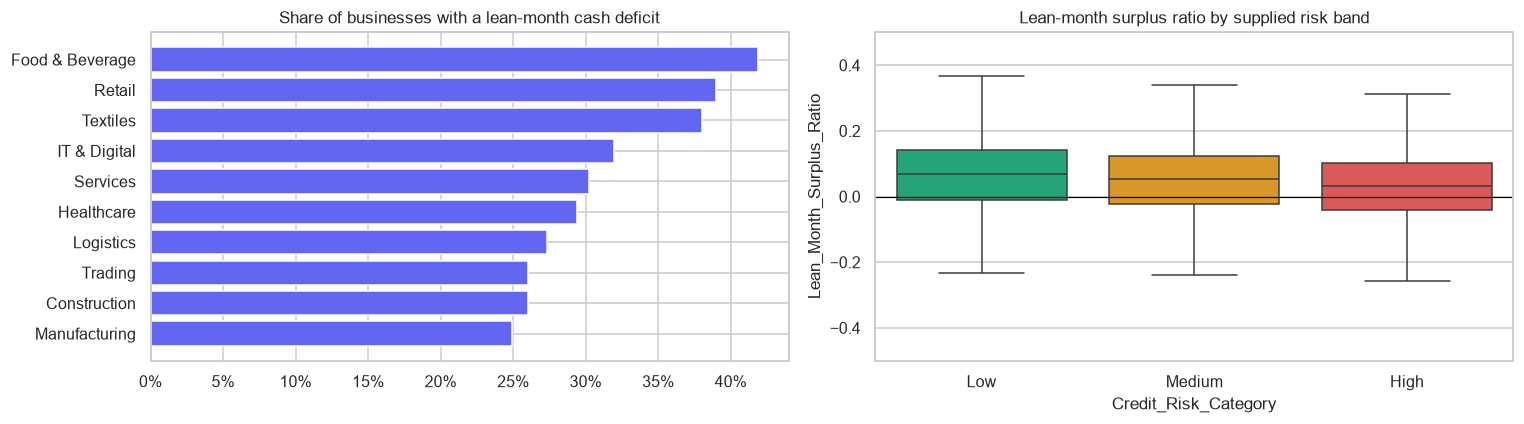

Businesses that run a cash deficit in their lean month: 31.8%


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
neg = df.assign(lean_deficit=df.Lean_Month_Surplus_INR < 0).groupby("Industry").lean_deficit.mean().sort_values()
axes[0].barh(neg.index, neg.values, color="#6366F1")
axes[0].set_title("Share of businesses with a lean-month cash deficit")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
order = ["Low", "Medium", "High"]
sns.boxplot(data=df, x="Credit_Risk_Category", y="Lean_Month_Surplus_Ratio", order=order, ax=axes[1],
            palette=["#10B981", "#F59E0B", "#EF4444"], fliersize=0)
axes[1].set_ylim(-0.5, 0.5)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Lean-month surplus ratio by supplied risk band")
plt.tight_layout()
plt.show()
print(f"Businesses that run a cash deficit in their lean month: {(df.Lean_Month_Surplus_INR < 0).mean():.1%}")

**Takeaway:** about a third of businesses cannot cover fixed costs in their lean month. That is too many to decline outright, so we use the stress test as a **loan-structuring signal** (seasonal or step-down EMI) rather than a hard cut-off.

## 2. How much signal does each feature carry?

Mutual information (MI) measures *any* relationship (not only linear) between a feature and the log-odds of default. We compare raw and derived features on the same scale.

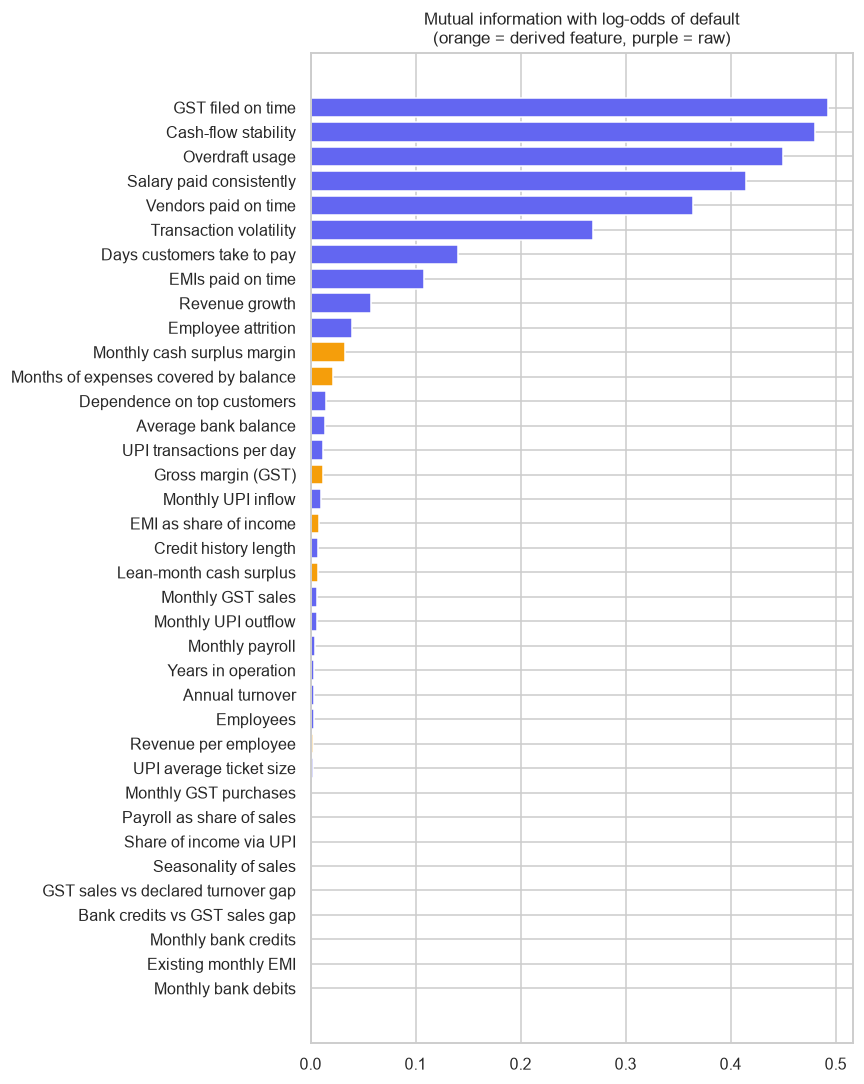

In [4]:
cols = NUMERIC_RAW + [c for c in DERIVED if c != "Thin_File"]
X = df[cols].fillna(-1)
smp = X.sample(15000, random_state=0).index
mi = pd.Series(mutual_info_regression(X.loc[smp], df.loc[smp, "logit_pd"], random_state=0), index=cols).sort_values()
colors = ["#F59E0B" if c in DERIVED else "#6366F1" for c in mi.index]
plt.figure(figsize=(8, 10))
plt.barh([LABELS.get(c, c) for c in mi.index], mi.values, color=colors)
plt.title("Mutual information with log-odds of default\n(orange = derived feature, purple = raw)")
plt.tight_layout()
plt.show()

**Takeaway:**
- Behavioural raw features (GST timeliness, cash-flow stability, overdraft, salary consistency) dominate.
- Among the derived features, **net surplus ratio** and **lean-month surplus** carry real signal. They summarise cash capacity in one number.
- Cross-source gaps carry little *risk* signal. That's expected: they exist to catch **fraud**, not to rank honest businesses.

## 3. Derived features vs default risk

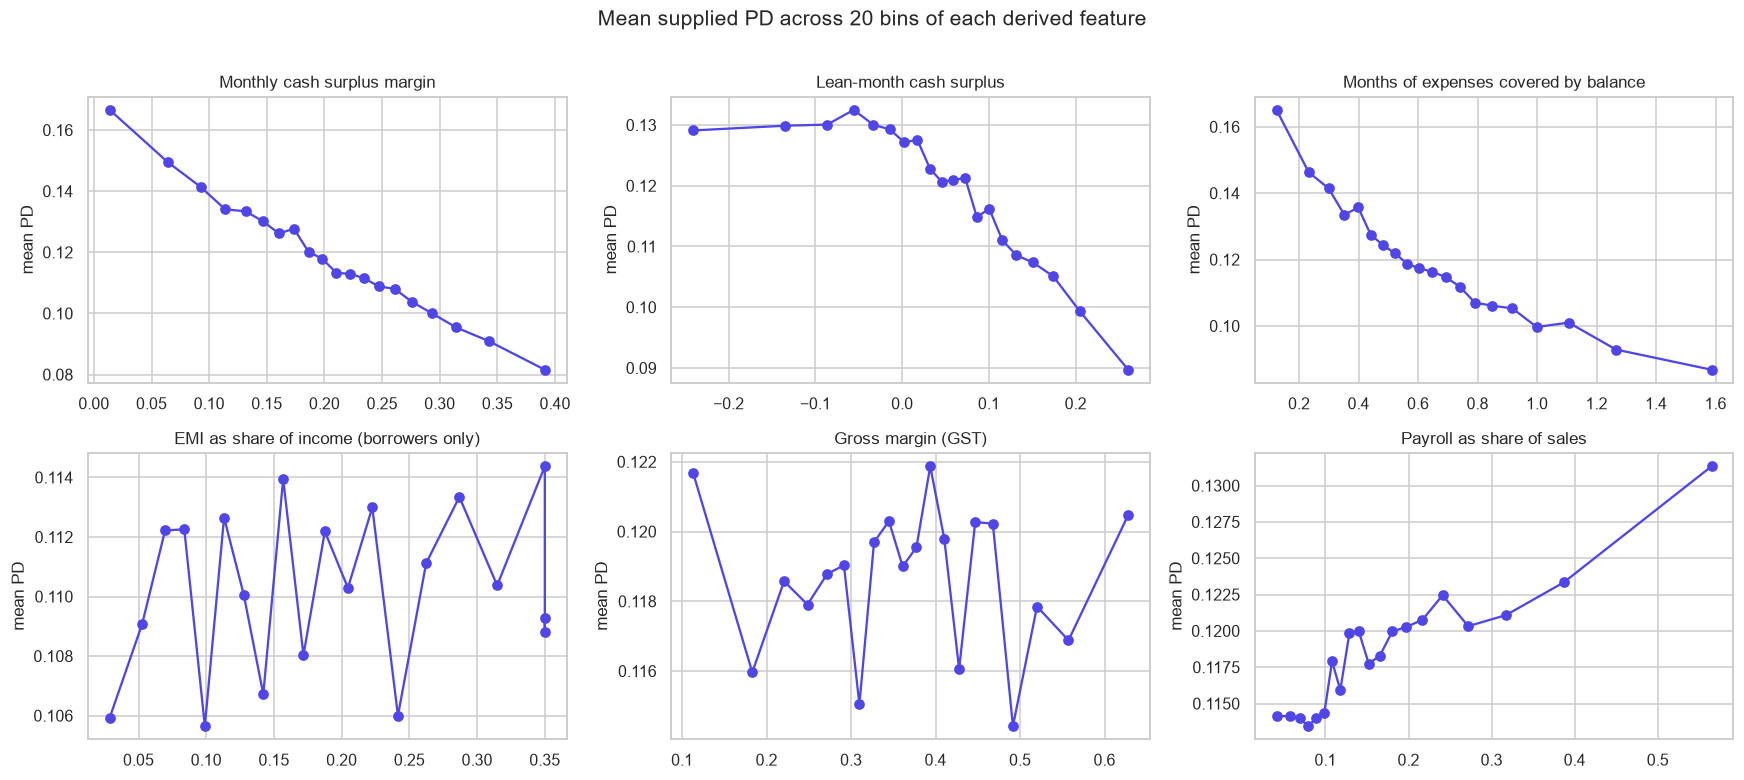

In [5]:
show = ["Net_Surplus_Ratio", "Lean_Month_Surplus_Ratio", "Balance_Cover_Months", "EMI_Burden", "Gross_Margin_GST", "Payroll_to_Sales"]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.flat, show):
    d = df[[col, "Probability_of_Default"]].dropna()
    if col == "EMI_Burden":
        d = d[d[col] > 0]
    b = pd.qcut(d[col], 20, duplicates="drop")
    g = d.groupby(b, observed=True).agg(x=(col, "median"), y=("Probability_of_Default", "mean"))
    ax.plot(g.x, g.y, marker="o", color="#4F46E5")
    ax.set_title(LABELS.get(col, col) + (" (borrowers only)" if col == "EMI_Burden" else ""))
    ax.set_ylabel("mean PD")
plt.suptitle("Mean supplied PD across 20 bins of each derived feature", y=1.01)
plt.tight_layout()
plt.show()

**Takeaway:** surplus ratio and lean-month surplus show clean monotonic relationships with PD, so we give them **monotonic constraints** (more surplus → never riskier). Gross margin and payroll share are nearly flat. We keep them for explanations and anomaly checks.

## 4. Redundancy check

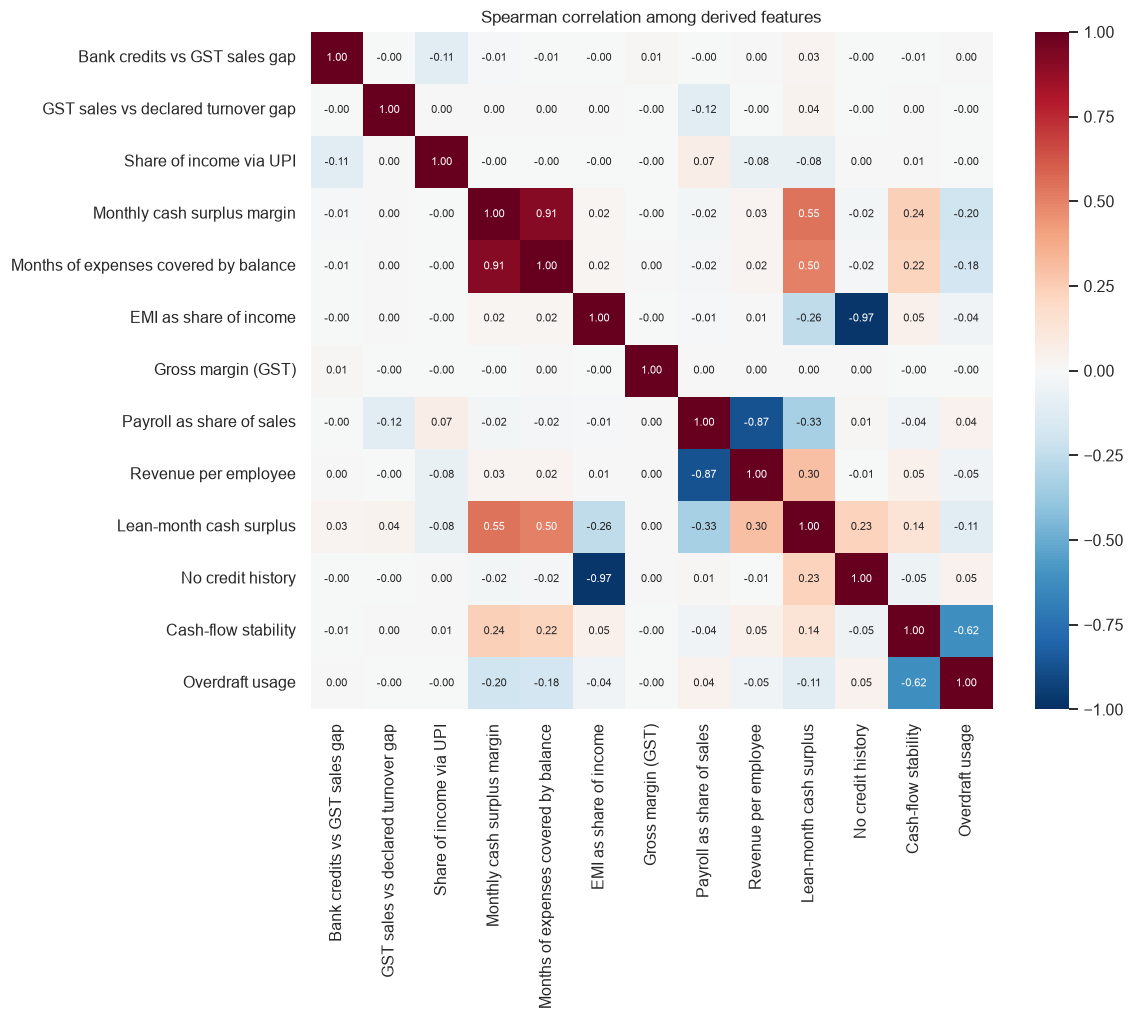

In [6]:
c = df[DERIVED + ["Cashflow_Stability_Index", "Overdraft_Usage_Ratio"]].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 7},
            xticklabels=[LABELS.get(i, i) for i in c.index], yticklabels=[LABELS.get(i, i) for i in c.index])
plt.title("Spearman correlation among derived features")
plt.show()

**Takeaway:** net surplus and lean-month surplus are strongly related (by construction) but answer different questions: the average month vs the worst month. Nothing else is redundant. Tree models handle correlated features well. For the linear baseline, Ridge regularisation absorbs it.

## 5. Peer-relative view

The same overdraft usage can be normal in one industry and alarming in another. The dashboard ranks each business within its **industry × location** peer group (50 groups, about 1,000 businesses each).

Peer groups: 50 · size min 248 · median 833 · max 2674


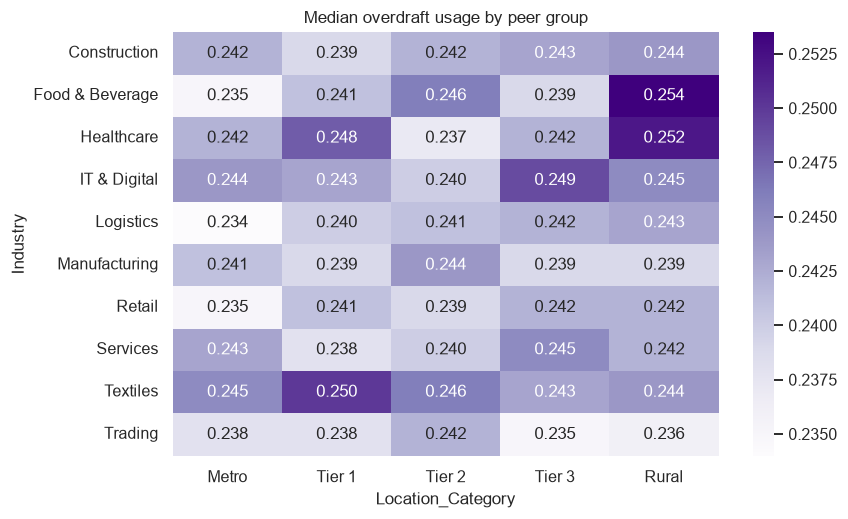

In [7]:
g = df.groupby(["Industry", "Location_Category"]).size()
print(f"Peer groups: {len(g)} · size min {g.min()} · median {int(g.median())} · max {g.max()}")
piv = df.pivot_table(index="Industry", columns="Location_Category", values="Overdraft_Usage_Ratio", aggfunc="median")
plt.figure(figsize=(8, 5))
sns.heatmap(piv[["Metro", "Tier 1", "Tier 2", "Tier 3", "Rural"]], annot=True, fmt=".3f", cmap="Purples")
plt.title("Median overdraft usage by peer group")
plt.show()

**Takeaway:** peer medians are very similar in this synthetic data. In real data they differ a lot. The peer benchmark is built so it adapts automatically, and it falls back to industry-only peers when a group has fewer than 200 businesses.

## 6. New candidate features: built and tested

We built 17 more features: the ideas in `docs/FEATURE_DICTIONARY.md` §10 plus a few interactions. Each answers a credit question an analyst would ask.

**This is an experiment only.** These features live in this notebook, not in the production model. They go into production only if they clearly improve it.

| Family | Feature | Formula | Credit question |
|---|---|---|---|
| Repayment capacity | `DSCR` | (credits − debits + EMI) ÷ EMI, borrowers only | How many times over can current cash flow pay existing EMIs? (classic bank metric) |
| Discipline | `Discipline_Index` | mean of GST, salary and vendor timeliness | One combined "pays everyone on time" signal, less noisy than each alone |
| Cash-flow quality | `Stability_x_Calm` | cash-flow stability × (1 − volatility) | Is income both steady *and* calm? |
| Stress | `Overdraft_x_Volatility` | overdraft use × volatility | Leaning on overdraft while income swings = fragile |
| Stress | `Overdraft_x_Seasonality` | overdraft use × seasonality | Seasonal business already using overdraft |
| Customer risk | `Concentration_x_Delay` | top-customer dependence × invoice delay | Few customers who also pay late = a single default can hurt |
| Working capital | `Working_Capital_Gap_Days` | invoice delay − days to pay vendors | Money stuck between paying suppliers and getting paid |
| Working capital | `Receivable_Days_vs_Cash_Days` | invoice delay ÷ days of expenses the balance covers | Can the cash buffer survive slow-paying customers? |
| Growth quality | `Growth_Quality` | growth × cash-flow stability | Growth backed by steady cash vs growth that burns cash |
| Growth quality | `Growth_per_Volatility` | growth ÷ volatility | Growth per unit of risk taken |
| Credit file | `Credit_Age_Ratio` | credit history months ÷ business age in months | Has the business used credit for most of its life? |
| Digital | `Digital_Footprint` | UPI share × log(daily UPI txns) | Many small digital receipts = steady, verifiable income |
| Digital | `UPI_Net_Flow_Ratio` | (UPI in − UPI out) ÷ UPI in | Is the UPI channel net positive? |
| Scale | `Log_Turnover` | log(turnover) | Size, without raw rupees dominating |
| Peer-relative | `Payroll_per_Employee_vs_Industry` | (payroll ÷ employees) ÷ industry median | Very low = under-reporting? very high = ghost staff? |
| Peer-relative | `Stability_vs_Peer`, `GST_Timeliness_vs_Peer` | value − peer-group median (industry × location) | Better or worse than similar businesses? |

**Leakage guard:** peer and industry medians are calculated on the **training rows only**, then applied to validation and test, just as they would be in production.

In [8]:
from sklearn.model_selection import train_test_split
from msme_health.config import RANDOM_STATE
from msme_health.features import prepare

strat = raw.Customer_Segment + "_" + raw.Credit_Risk_Category
idx_tr, idx_tmp = train_test_split(raw.index, test_size=0.30, stratify=strat, random_state=RANDOM_STATE)
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50, stratify=strat[idx_tmp], random_state=RANDOM_STATE)


def add_candidates(d: pd.DataFrame, train_idx) -> pd.DataFrame:
    """The 17 candidate features. Peer medians are learned on train_idx only."""
    credits, debits = d.Monthly_Bank_Credits_INR, d.Monthly_Bank_Debits_INR
    emi = d.Monthly_Loan_EMI_INR.fillna(0)
    n = pd.DataFrame(index=d.index)
    n["DSCR"] = ((credits - debits + emi) / emi.where(emi > 0)).clip(-10, 50)
    n["Discipline_Index"] = d[["GST_Filing_Timeliness_Pct", "Salary_Consistency_Pct", "Vendor_Payment_Timeliness_Pct"]].mean(axis=1)
    n["Stability_x_Calm"] = d.Cashflow_Stability_Index * (1 - d.Transaction_Volatility_Index)
    n["Overdraft_x_Volatility"] = d.Overdraft_Usage_Ratio * d.Transaction_Volatility_Index
    n["Overdraft_x_Seasonality"] = d.Overdraft_Usage_Ratio * d.Seasonality_Index
    n["Concentration_x_Delay"] = d.Customer_Concentration_Ratio * d.Avg_Invoice_Payment_Delay_Days
    vendor_days = (100 - d.Vendor_Payment_Timeliness_Pct) / 100 * 60   # assume late vendors are paid within ~60 days
    n["Working_Capital_Gap_Days"] = d.Avg_Invoice_Payment_Delay_Days - vendor_days
    cash_days = d.Average_Bank_Balance_INR / (debits / 30)
    n["Receivable_Days_vs_Cash_Days"] = d.Avg_Invoice_Payment_Delay_Days / cash_days
    n["Growth_Quality"] = d.Revenue_Growth_Rate_Pct * d.Cashflow_Stability_Index
    n["Growth_per_Volatility"] = d.Revenue_Growth_Rate_Pct / d.Transaction_Volatility_Index
    n["Credit_Age_Ratio"] = d.Credit_History_Months / (d.Years_in_Operation * 12)
    n["Digital_Footprint"] = (d.Monthly_UPI_Inflow_INR / credits) * np.log1p(d.UPI_Daily_Txn_Count)
    n["UPI_Net_Flow_Ratio"] = (d.Monthly_UPI_Inflow_INR - d.Monthly_UPI_Outflow_INR) / d.Monthly_UPI_Inflow_INR
    n["Log_Turnover"] = np.log1p(d.Annual_Turnover_INR)

    ppe = d.Monthly_Payroll_INR / d.Employee_Count
    ind_med = ppe[train_idx].groupby(d.Industry[train_idx]).median()
    n["Payroll_per_Employee_vs_Industry"] = ppe / d.Industry.map(ind_med)
    peer = d.Industry + " | " + d.Location_Category
    for src, name in [("Cashflow_Stability_Index", "Stability_vs_Peer"), ("GST_Filing_Timeliness_Pct", "GST_Timeliness_vs_Peer")]:
        med = d.loc[train_idx, src].groupby(peer[train_idx]).median()
        n[name] = d[src] - peer.map(med)
    return n


NEW = add_candidates(raw, idx_tr)
NEW.describe(percentiles=[0.01, 0.5, 0.99]).T.round(3)

,count,mean,std,min,1%,50%,99%,max
DSCR,17444.0,2.726,2.042,-3.951,0.909,2.110,11.871,23.993
Discipline_Index,50000.0,83.528,6.714,56.333,66.866,83.867,97.633,100.000
Stability_x_Calm,50000.0,0.492,0.118,0.086,0.227,0.492,0.766,0.960
Overdraft_x_Volatility,50000.0,0.074,0.047,0.000,0.008,0.064,0.223,0.365
Overdraft_x_Seasonality,50000.0,0.087,0.054,0.000,0.007,0.076,0.252,0.491
Concentration_x_Delay,50000.0,5.853,4.799,0.000,0.161,4.583,23.171,59.441
Working_Capital_Gap_Days,50000.0,3.329,9.066,-21.460,-11.360,1.720,32.120,83.120
Receivable_Days_vs_Cash_Days,50000.0,1.400,8.013,0.000,0.021,0.670,10.048,754.467
Growth_Quality,50000.0,6.590,11.591,-42.021,-19.061,6.142,35.720,65.446
Growth_per_Volatility,50000.0,40.105,82.609,-1160.000,-132.781,32.782,290.616,2146.667


### 6a. Do the new features relate to default risk?

Spearman correlation with PD: the sign says the direction (+ raises risk), the size says the strength. We compare with the strongest single raw feature.

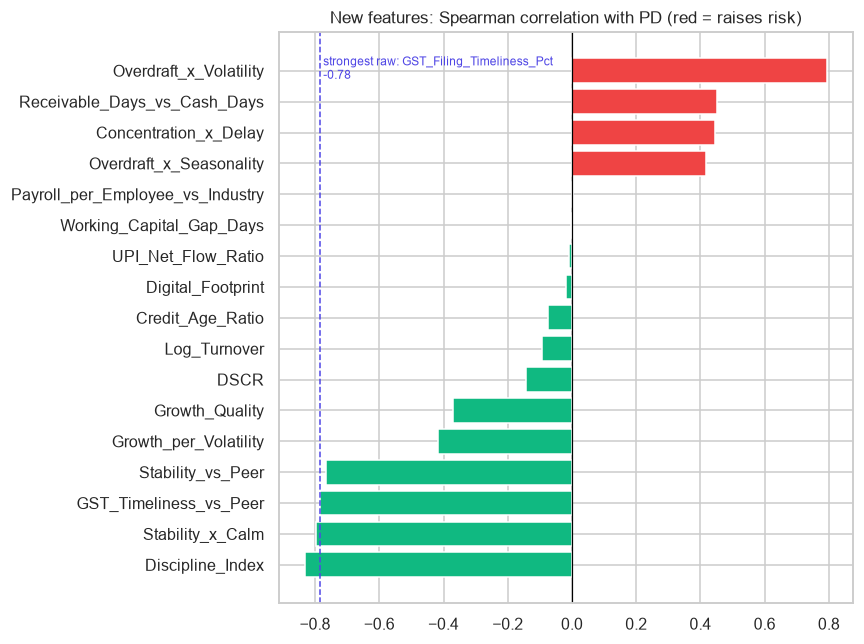

In [9]:
sp = NEW.corrwith(df.Probability_of_Default, method="spearman").sort_values()
best_raw = df[NUMERIC_RAW].corrwith(df.Probability_of_Default, method="spearman").abs().sort_values().index[-1]
best_raw_v = df[best_raw].corr(df.Probability_of_Default, method="spearman")
plt.figure(figsize=(8, 6))
plt.barh(sp.index, sp.values, color=["#EF4444" if v > 0 else "#10B981" for v in sp.values])
plt.axvline(best_raw_v, ls="--", color="#4F46E5", lw=1)
plt.axvline(0, color="black", lw=0.8)
plt.text(best_raw_v, len(sp) - 0.5, f" strongest raw: {best_raw}\n {best_raw_v:.2f}", color="#4F46E5", fontsize=8, va="top")
plt.title("New features: Spearman correlation with PD (red = raises risk)")
plt.tight_layout()
plt.show()

### 6b. The real test: does the model get better?

A correlation alone does not prove value: a new feature may just repeat what the model already knows. So we run an **ablation**:
1. Train the production LightGBM setup on the **44 current features** (baseline).
2. Train it again with **all 44 + 17 new features**.
3. Train it once per new feature: **44 + that one feature**.

Same train/validation/test split as the production model (35k / 7.5k / 7.5k). The metric is R² of the log-odds of PD on the **test** set.

In [10]:
import lightgbm as lgb
from sklearn.metrics import r2_score

X_base = prepare(raw)
z = df["logit_pd"]


def fit_score(X):
    m = lgb.LGBMRegressor(n_estimators=3000, learning_rate=0.05, num_leaves=31, min_child_samples=50,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                          random_state=RANDOM_STATE, verbose=-1)
    m.fit(X.loc[idx_tr], z[idx_tr], eval_set=[(X.loc[idx_va], z[idx_va])], callbacks=[lgb.early_stopping(100, verbose=False)])
    return r2_score(z[idx_te], m.predict(X.loc[idx_te])), m


base_r2, _ = fit_score(X_base)
X_all = pd.concat([X_base, NEW], axis=1)
all_r2, m_all = fit_score(X_all)
one = pd.Series({c: fit_score(pd.concat([X_base, NEW[[c]]], axis=1))[0] - base_r2 for c in NEW.columns})
print(f"Baseline, 44 features:        test R² (log-odds PD) = {base_r2:.4f}")
# Noise check: the same 44 features, only the random seed changes (row/column sampling inside LightGBM).
seed_r2 = []
for seed in [1, 2, 3, 4]:
    m = lgb.LGBMRegressor(n_estimators=3000, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8,
                          subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=seed, verbose=-1)
    m.fit(X_base.loc[idx_tr], z[idx_tr], eval_set=[(X_base.loc[idx_va], z[idx_va])], callbacks=[lgb.early_stopping(100, verbose=False)])
    seed_r2.append(r2_score(z[idx_te], m.predict(X_base.loc[idx_te])))
print(f"Same 44 features, 4 other seeds:  {min(seed_r2):.4f} – {max(seed_r2):.4f}  (noise band)")
print(f"With all 17 new (61 features): test R² (log-odds PD) = {all_r2:.4f}  ({all_r2 - base_r2:+.4f})")

Baseline, 44 features:        test R² (log-odds PD) = 0.8980


Same 44 features, 4 other seeds:  0.8983 – 0.8997  (noise band)
With all 17 new (61 features): test R² (log-odds PD) = 0.9005  (+0.0025)


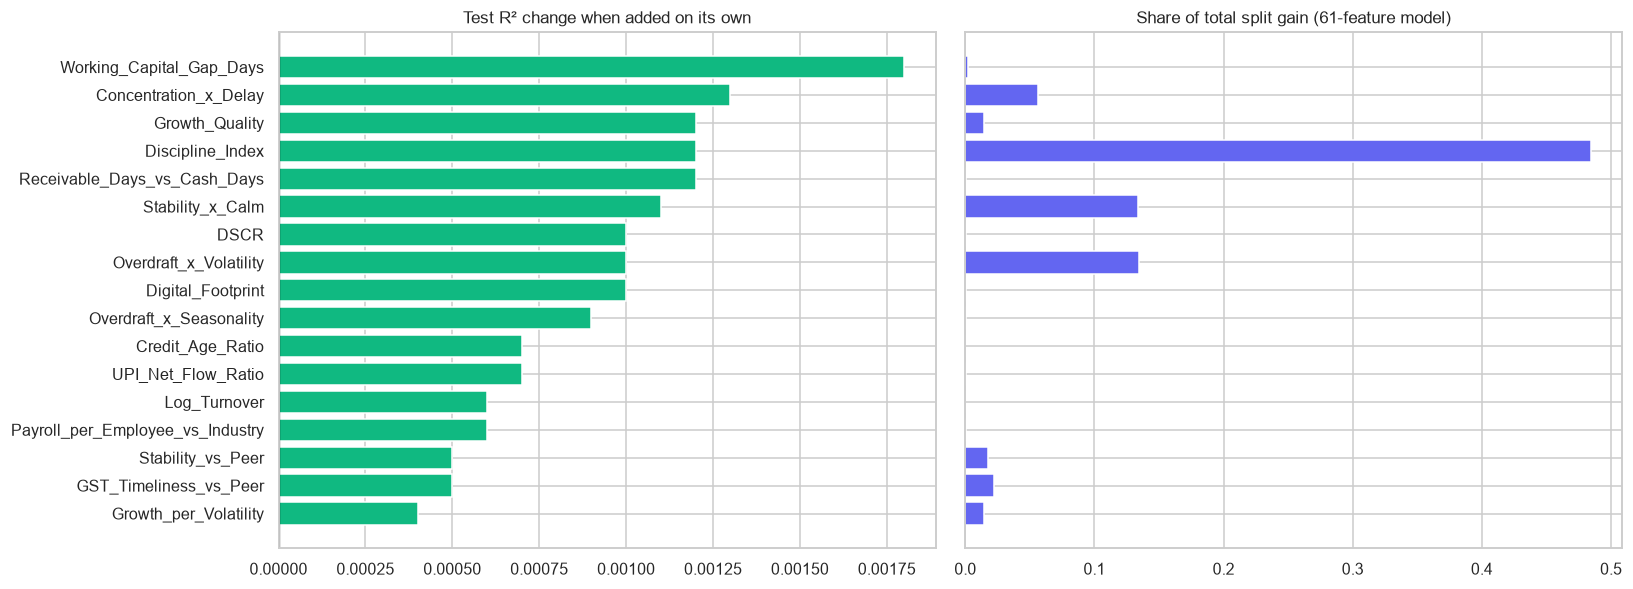

,R² change when added alone,share of model gain (all-in)
Working_Capital_Gap_Days,0.0018,0.0017
Concentration_x_Delay,0.0013,0.0565
Growth_Quality,0.0012,0.0145
Discipline_Index,0.0012,0.4845
Receivable_Days_vs_Cash_Days,0.0012,0.0006
Stability_x_Calm,0.0011,0.1338
DSCR,0.0010,0.0002
Overdraft_x_Volatility,0.0010,0.1341
Digital_Footprint,0.0010,0.0004
Overdraft_x_Seasonality,0.0009,0.0004


In [11]:
gain = pd.Series(m_all.booster_.feature_importance("gain"), index=X_all.columns)
share = (gain / gain.sum())[NEW.columns]
res = pd.DataFrame({"R² change when added alone": one.round(4), "share of model gain (all-in)": share.round(4)})
res = res.sort_values("R² change when added alone", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
axes[0].barh(res.index[::-1], res.iloc[::-1, 0], color=["#10B981" if v > 0 else "#94A3B8" for v in res.iloc[::-1, 0]])
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("Test R² change when added on its own")
axes[1].barh(res.index[::-1], res.iloc[::-1, 1], color="#6366F1")
axes[1].set_title("Share of total split gain (61-feature model)")
plt.tight_layout()
plt.show()
res

### 6c. Why the gain is small, and what it means

**Reading the numbers:**
- Re-running the *same* 44-feature model with a different random seed moves test R² between **0.898 and 0.900**. That is the noise band.
- Every new feature added on its own lands **inside that band** (+0.0004 to +0.0018). On its own, none is a proven improvement.
- All 17 together reach **0.9005**, just above the band: a small but real gain of about **0.001–0.002**.

**Why so small:**
- **The model is already near the ceiling.** The supplied PD was *generated* from the raw behavioural columns plus random noise. The 44-feature model already explains about 90% of it, and a plain Ridge model does about the same. The remaining ~10% looks like noise, and no feature can predict noise.
- **The model leans on the discipline index and the interactions** (discipline index 48% of the new features' gain; stability × calm and overdraft × volatility 13% each). But they are combinations of columns the model already has, so it mostly *re-uses* the same information through a shorter path. LightGBM can build most interactions by itself.
- **DSCR, working capital, credit age, peer-relative and digital features are barely used** on this data, because the PD formula never used them.

**Decision:** keep the production model at 44 features. A 0.1–0.2 point R² gain is not worth more inputs to collect, validate, monitor and explain.

**With real data, this would likely change.** Real defaults depend on things a synthetic formula leaves out: repayment capacity (DSCR), working-capital squeeze, and how a business compares with its peers. These are the first features I would re-test once observed defaults are available. Some are also useful **for underwriters to read** even with no accuracy gain: DSCR and the discipline index are terms every credit officer already knows.